# Predicción de la volatilidad con ARCH/GARCH

In [ ]:
import datetime as dt
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics import tsaplots
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_arch
import statsmodels.graphics.tsaplots as sgt
from arch import arch_model
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [ ]:
file_path = "BTC-Daily.csv"
data = pd.read_csv(file_path)
data = data[["date","close"]]
data.date = pd.to_datetime(data.date)
data.set_index("date", inplace = True)
data.index = data.index.sort_values()
data.head()

,close
date,
2014-11-28,43185.48
2014-11-29,43178.98
2014-11-30,37712.68
2014-12-01,39146.66
2014-12-02,39231.64


Calculamos la rentabilidad del bitcoin.

In [37]:
data["Return"] = 100*data["close"].pct_change()
data.dropna(inplace=True)
data.head()

,close,Return,vol
date,,,
2014-11-30,37712.68,-12.659632,160.266284
2014-12-01,39146.66,3.802382,14.458106
2014-12-02,39231.64,0.217081,0.047124
2014-12-03,38376.88,-2.178752,4.746959
2014-12-04,37274.18,-2.873345,8.256109


Visualizamos la serie

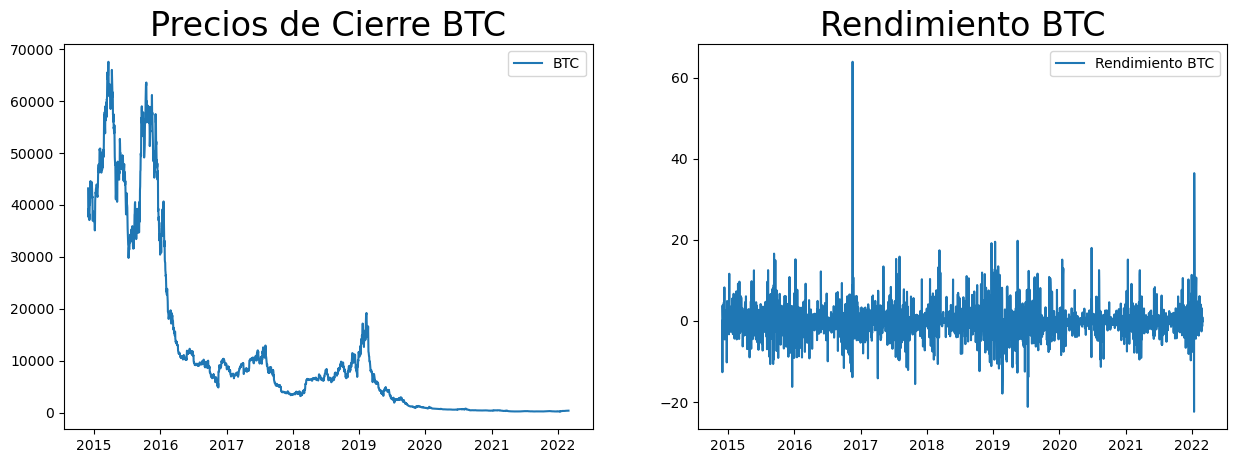

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(15,5))

ax[0].plot(data.close, label = "BTC")
ax[0].set_title("Precios de Cierre BTC", size = 24)
ax[0].legend()

ax[1].plot(data.Return, label = "Rendimiento BTC")
ax[1].set_title("Rendimiento BTC", size = 24)
ax[1].legend()

Si graficamos el cuadrado del retorno/rendimiento podremos comprobar visualmente los periodos de alta y baja volatilidad.

In [28]:
data["vol"] = data.Return.mul(data.Return)

C:\Users\icalvo\AppData\Local\Temp\ipykernel_31784\1010655863.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0].legend()
C:\Users\icalvo\AppData\Local\Temp\ipykernel_31784\1010655863.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1].legend()


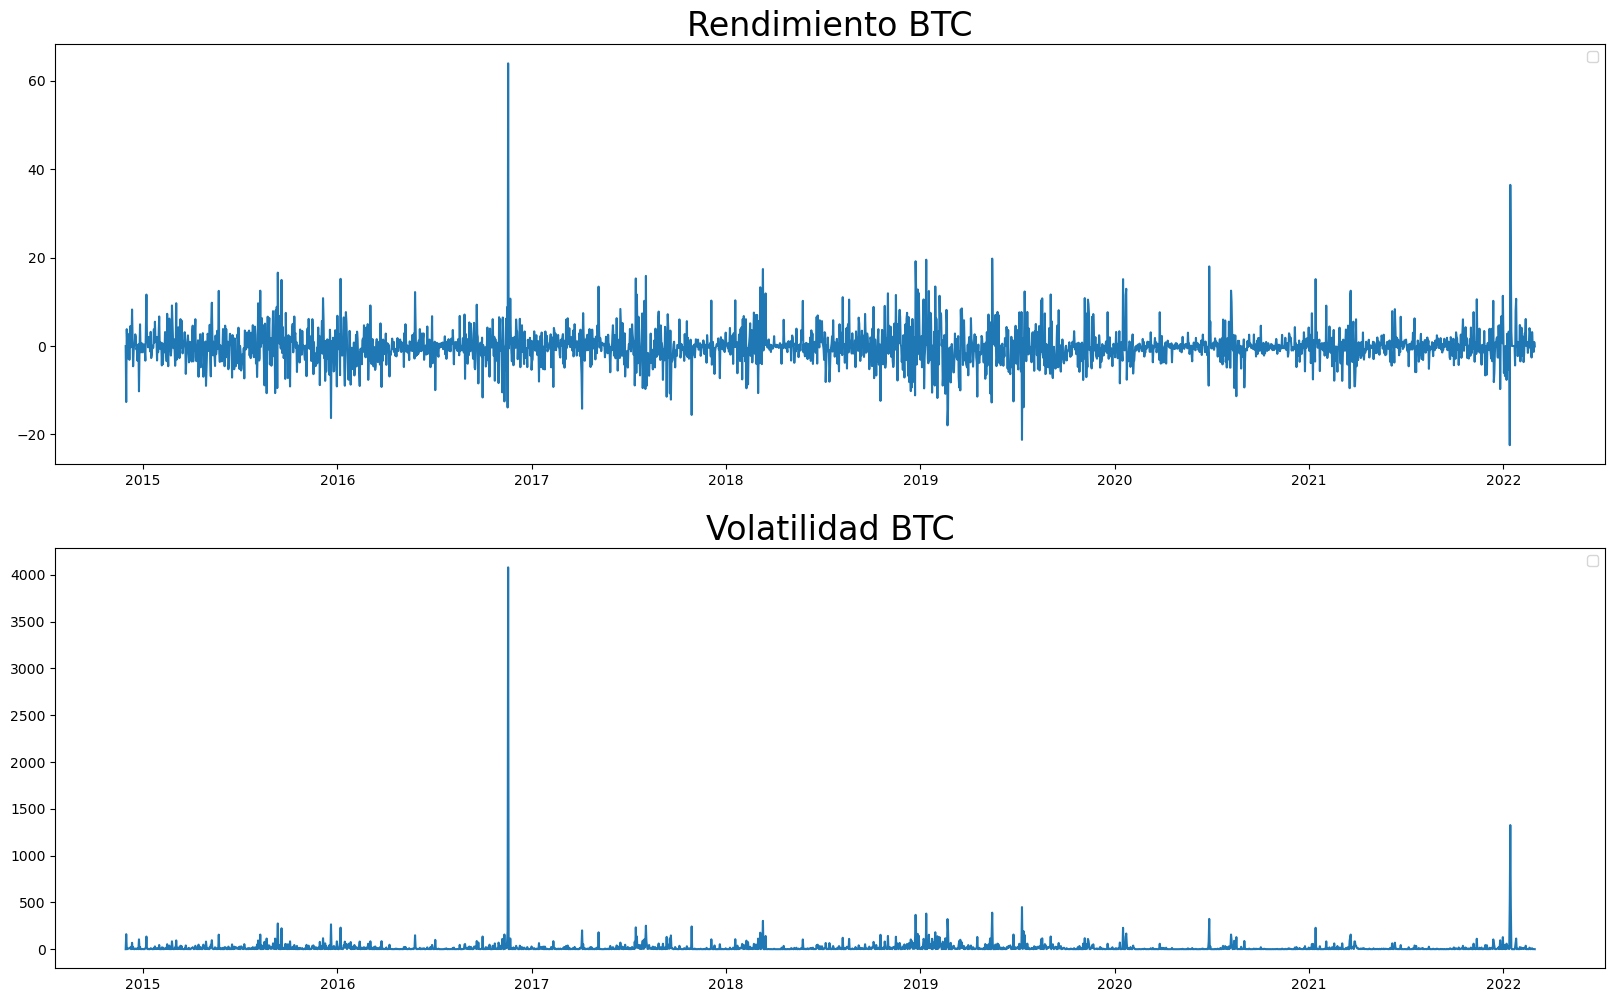

In [29]:
fig, ax = plt.subplots(2,1, figsize=(20, 12))

ax[0].plot(data.Return)
ax[0].set_title("Rendimiento BTC", size = 24)
ax[0].legend()

ax[1].plot(data.vol)
ax[1].set_title("Volatilidad BTC", size = 24)
ax[1].legend()

Vamos a comprobar que el rendimiento no es estacionario. Para eso le pasadmos los test de raiz unitaria.

In [30]:
adf_result = adfuller(data.Return)
kpss_result = kpss(data.Return)
print("ADF p-valor",adf_result[1])
print("KPSS p-valor", kpss_result[1])

ADF p-valor 0.0
KPSS p-valor 0.1


C:\Users\icalvo\AppData\Local\Temp\ipykernel_31784\1777099555.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_result = kpss(data.Return)


In [31]:
lm_test = het_arch(data.Return)

print("Resultados del ARCH test:")
print(f"Estadístico LM: {lm_test[0]:.4f}")
print(f"P-valor LM: {lm_test[1]:.4f}")
print(f"Estadístico F: {lm_test[2]:.4f}")
print(f"P-valor F: {lm_test[3]:.4f}")

Resultados del ARCH test:
Estadístico LM: 39.4246
P-valor LM: 0.0000
Estadístico F: 3.9856
P-valor F: 0.0000


El p-valor < 0.05, por lo tanto, la serie presenta heterocedasticidad y por lo tanto no es estacionaria en varianza.

Calculamos las volatilidades históricas en primer lugar

In [14]:
# Calculate daily std of returns
std_daily = data['Return'].std()
print(f'Daily volatility: {round(std_daily,2)}%')

# Convert daily volatility to monthly volatility
std_monthly = np.sqrt(21) * std_daily
print(f'\nMonthly volatility: {round(std_monthly,2)}%')

# Convert daily volatility to annaul volatility
std_annual = np.sqrt(252) * std_daily
print(f'\nAnnual volatility: {round(std_annual,2)}%')

Daily volatility: 4.12%

Monthly volatility: 18.86%

Annual volatility: 65.34%


Comprobamos si la rentabilidad tiene estructura.

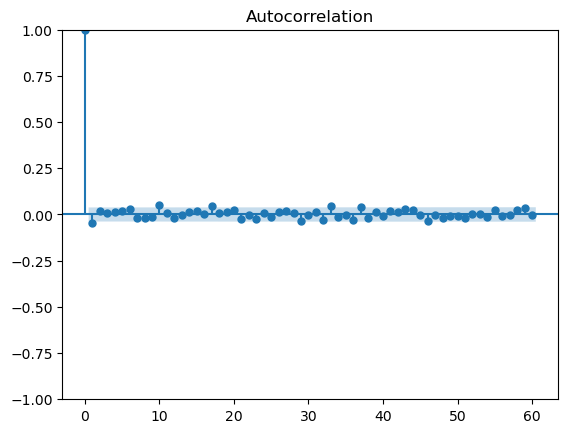

In [40]:
tsaplots.plot_acf(data.Return, lags=60);

No se observa ningún patrón evitende en el rendimiento de la serie por lo que trabajaremos directamente con la variable.

Dibujamos los diagramas de autocorrelación y autocorrelación parcial del rendimiento al cuadrado.


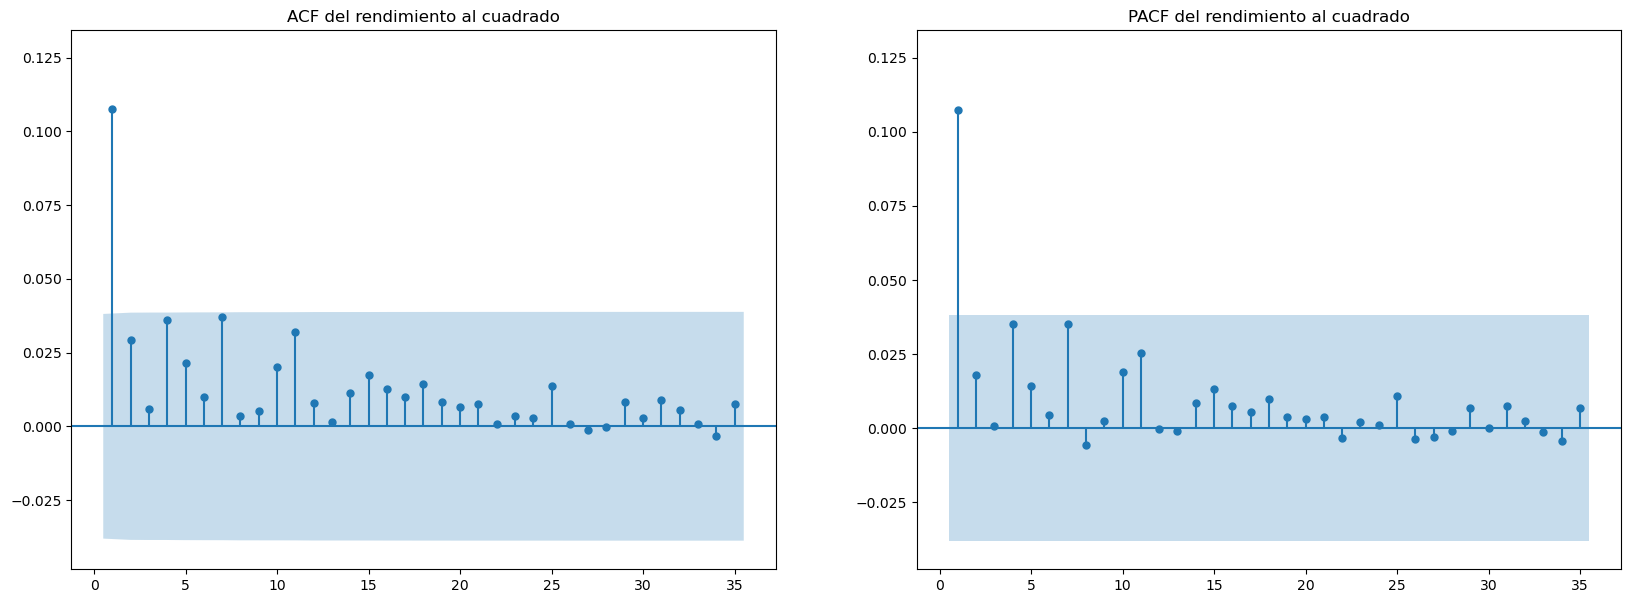

In [42]:

plt.rcParams["figure.figsize"] = (20, 7)
rent2 = data["Return"].mul(data["Return"])
fig, ax = plt.subplots(1,2)

sgt.plot_acf(rent2,ax=ax[0], zero=False,auto_ylims=True, title="ACF del rendimiento al cuadrado")
sgt.plot_pacf(rent2,ax=ax[1],zero=False,auto_ylims=True,title="PACF del rendimiento al cuadrado");

## Modelización de la volatilidad

In [43]:
# GARCH(1,1)
garchm = arch_model(data['Return'], p = 1, q = 1,
                      mean = 'constant', vol = 'GARCH', dist = 'normal')

# Fit the model
gm_result = garchm.fit(update_freq = 4)

Iteration:      4,   Func. Count:     26,   Neg. LLF: 7141.910132292787
Iteration:      8,   Func. Count:     51,   Neg. LLF: 7140.570290611364
Optimization terminated successfully    (Exit mode 0)
            Current function value: 7140.569945111545
            Iterations: 11
            Function evaluations: 65
            Gradient evaluations: 11


In [44]:
print(gm_result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                 Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -7140.57
Distribution:                  Normal   AIC:                           14289.1
Method:            Maximum Likelihood   BIC:                           14312.7
                                        No. Observations:                 2649
Date:                Wed, Sep 30 2026   Df Residuals:                     2648
Time:                        17:18:12   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu            -0.0966  6.027e-02     -1.603      0.109 [ -0.215,



### Output de la iteración
Le cuesta 11 iteraciones hasta que converge.
Normalemente, un considera que un ajuste es mejor que el anterior cuando Cuando disminuye el LLF (LogLikelihood). En este caso tenermos el LLF Negativo por lo tanto aumenta hasta que converge a un valor máximo. Podemos elegir cada cuantas iteraciones queremos que nos enseñe el output añadiendo *update_freq = N* al ajuste del modelo.
### Resultados del modelo ARCH
- **Mean Model**: considera que la media de la serie temporal es constante. Lo coge por defecto si no le especificamos nada.
- **Vol Model**: modelo utilizado para la varianza
- **Distribution**: distrución de los residuos
- **Method**: método para encontrar los coeficientes del ajuste
- **Df model**: grados de libertad (Degree of Freedom) o número de coeficientes que ha calculado.
- **R-squared** y **Adj. R-squared**: en este caso tenemos un -0.000. Esto significa que tenemos un valor negativo pero podemos redondearlo a cero, ya que solo tiene en cuenta tres decimales. R2 nos explica como varía la serie con respecto a la media. No es un valor muy representativo de los modelos ARCH. 
- **Log-Likelihood**:Este parámetros nos da la calidad del ajuste. Si lo comparásemos con el obtenido en un ARMA, este será, muy probablemente, más alto y por lo tanto el ajuste será mejor.

### Resultados del modelo que ajusta la media de la serie
Como se considera una media constante, tendremos un **único coeficiente**. 

Para saber si nuestro los coeficientes del ajuste son significativos **P>|t|** < 0.05, ya que estamos teniendo en cuenta el 95% del intervalo de confianza. 

### Resultados del modelo que ajusta la volatilidad de la serie
- **omega**: representa $alpha_0$.


Parámetros más importantes para la configuración del modelo:
- mean: "Constant", "Zero", "LS", "AR", "ARX", "HAR" and "HARX".
- vol: especificamos el tipo de modelo para la varianza ("ARCH", "GARCH")
- p y q


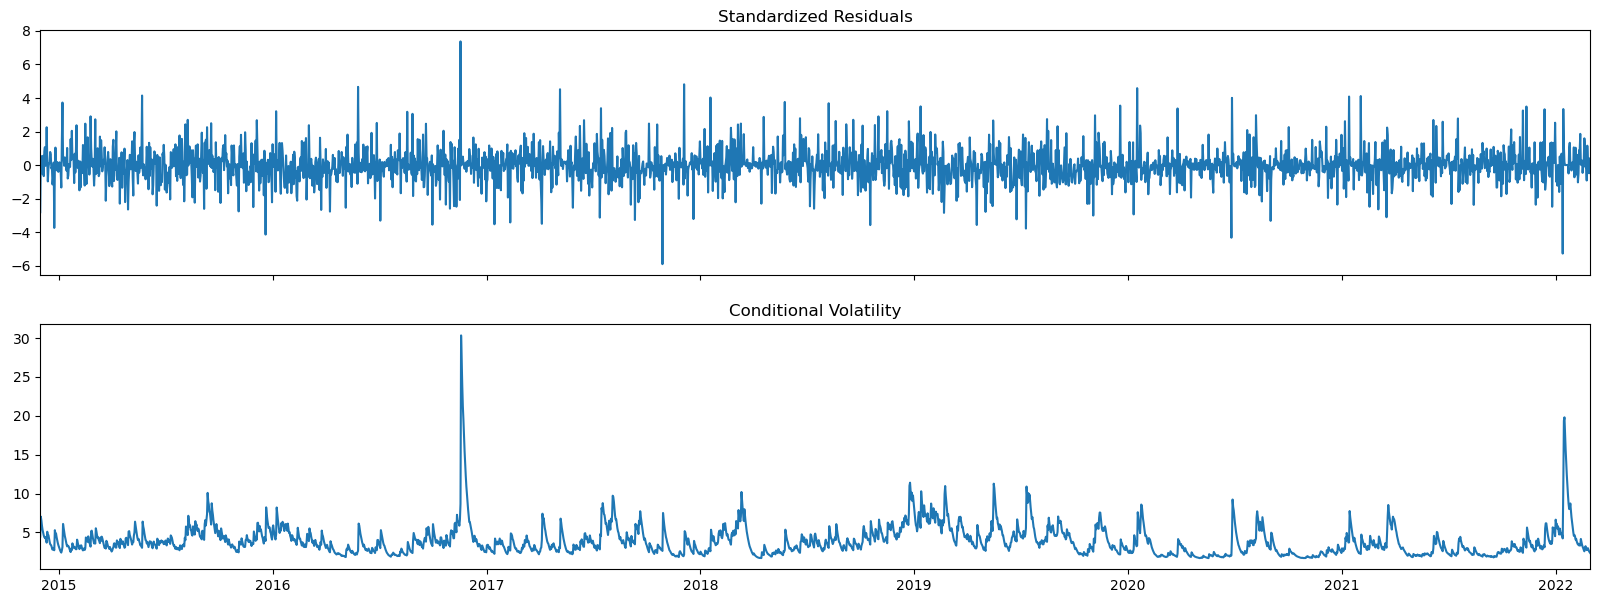

In [45]:
gm_result.plot()
plt.show()

Teniendo en cuenta la información del resumen, estamos ajustando bien el modelos de la volatilidad, pero no el de la media de la serie. Esto puede deberse al elevado choque que se aprecia en la serie. Para resolver este tipo de asimetrías utilizaremos el modelo EGARCH.

In [ ]:
# GARCH(1,1)
garchm = arch_model(data['Return'], p = 1, q = 1, o=1,
                      mean = 'constant', vol = 'EGARCH', dist = 'normal')
# Fit the model
gm_result = garchm.fit(update_freq = 4)

Iteration:      4,   Func. Count:     37,   Neg. LLF: 392628.0986323354
Iteration:      8,   Func. Count:     68,   Neg. LLF: 7071.722748848796
Iteration:     12,   Func. Count:     92,   Neg. LLF: 7071.705733950342
Optimization terminated successfully    (Exit mode 0)
            Current function value: 7071.705709833179
            Iterations: 15
            Function evaluations: 109
            Gradient evaluations: 15


In [47]:
print(gm_result.summary())

                     Constant Mean - EGARCH Model Results                     
Dep. Variable:                 Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                     EGARCH   Log-Likelihood:               -7071.71
Distribution:                  Normal   AIC:                           14153.4
Method:            Maximum Likelihood   BIC:                           14182.8
                                        No. Observations:                 2649
Date:                Wed, Sep 30 2026   Df Residuals:                     2648
Time:                        17:18:19   Df Model:                            1
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
mu            -0.1731  5.798e-02     -2.986  2.831e-03 [ -0.2

## Comprobación de la calidad del modelo

Vemos que el valor absoluto de t > 2 y que el p-valor < 0.05 en todos los caso, por lo que podríamos aceptar todos los coeficientes como buenos ajustes. Comprobemos que el residuo del ajuste no tiene autocorrelación.

In [48]:
gm_std_resid = gm_result.std_resid


In [51]:
lm_test = het_arch(gm_std_resid)

print("Resultados del ARCH test:")
print(f"Estadístico LM: {lm_test[0]:.4f}")
print(f"P-valor LM: {lm_test[1]:.4f}")
print(f"Estadístico F: {lm_test[2]:.4f}")
print(f"P-valor F: {lm_test[3]:.4f}")

Resultados del ARCH test:
Estadístico LM: 10.4634
P-valor LM: 0.4008
Estadístico F: 1.0461
P-valor F: 0.4014


## Predicción de la volatilidad


In [57]:
index = data.index
# Índice en orden ascendente (del dato más antiguo al más reciente)
start_loc = 0
end_loc = np.where(index >= '2021-01-01')[0].min()

- Expanding rolling window forecast

In [58]:
forecasts = {}
for i in range(70):
    res = garchm.fit(first_obs = start_loc, last_obs = i + end_loc, disp = 'off')
    temp = res.forecast(horizon=1, reindex=True).variance
    fcast = temp.iloc[i + end_loc - 1]
    forecasts[fcast.name] = fcast
print(' Done!')
pred_variance_expand = pd.DataFrame(forecasts).T

 Done!


- Fixed rolling window forecast

In [59]:
forecasts = {}
for i in range(70):
    res = garchm.fit(first_obs=start_loc + i, last_obs=i + end_loc, disp='off')
    temp = res.forecast(horizon=1, reindex=True).variance
    fcast = temp.iloc[i + end_loc - 1]
    forecasts[fcast.name] = fcast
print(' Done!')
pred_variance_fixed = pd.DataFrame(forecasts).T

 Done!


Comparamos las predicciones

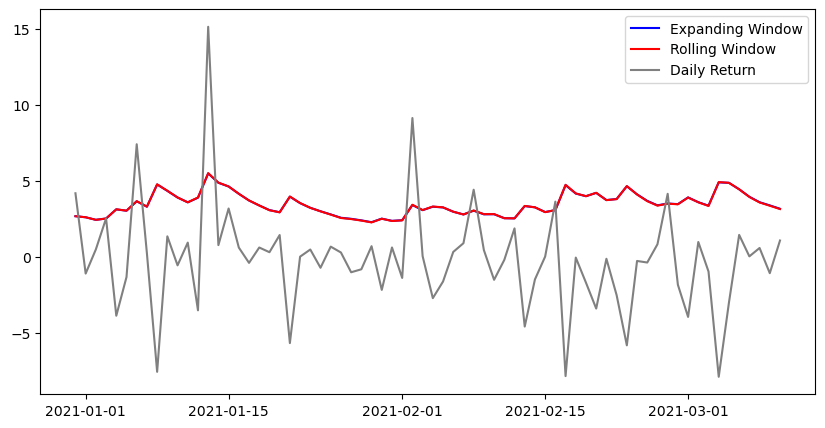

In [60]:
# Calculate volatility from variance forecast with an expanding window
pred_vol_expand = np.sqrt(pred_variance_expand)

# Calculate volatility from variance forecast with a fixed rolling window
pred_vol_fixedwin = np.sqrt(pred_variance_fixed)

# Plot results
plt.figure(figsize=(10,5))

# Plot volatility forecast with an expanding window
plt.plot(pred_vol_expand, color = 'blue', label='Expanding Window')

# Plot volatility forecast with a fixed rolling window
plt.plot(pred_vol_fixedwin, color = 'red', label='Rolling Window')

plt.plot(data.Return.loc[pred_variance_expand.index], color = 'grey', label='Daily Return')

plt.legend()
plt.show()

Ahora evaluaremos la calidad de la predicción.

In [61]:
def evaluate(observation, forecast): 
    # Call sklearn function to calculate MAE
    mae = mean_absolute_error(observation, forecast);
    print('Mean Absolute Error (MAE): {:.3g}'.format(mae))
    # Call sklearn function to calculate MSE
    mse = mean_squared_error(observation, forecast);
    print('Mean Squared Error (MSE): {:.3g}'.format(mse))
    return mae, mse

In [62]:
# la volatilidad puede estimarse como la varianza del rendimiento.
#Para calcular la evolución, hacemos el cálculo para cada instante temporal y
# tenemos en cuenta el intervalo temporal que queremos comparar con las predicciones
vol = data['Return'].sub(data['Return'].mean()).pow(2)[pred_variance_expand.index]
var = data['Return'].sub(data['Return'].mean())[pred_variance_expand.index]



In [63]:
evaluate(vol, pred_vol_expand);

Mean Absolute Error (MAE): 11.8
Mean Squared Error (MSE): 1.04e+03


In [47]:
evaluate(vol, pred_vol_fixedwin);

Mean Absolute Error (MAE): 11.7
Mean Squared Error (MSE): 1.04e+03
